![Image in a markdown cell](https://cursos.utnba.centrodeelearning.com/pluginfile.php/1/theme_space/customlogo/1738330016/Logo%20UTN%20Horizontal.png)


# **Diplomado de Ciencia de Datos y Análisis Avanzado**
# **Unidad 5: Modelado Predictivo I**: Regresión y Clasificación

---

# **Proyecto: Predicción de Abandono de Clientes**

## **Curso:** Diplomado en Ciencia de Datos

# **Objetivo:**
## El objetivo de este proyecto es construir y evaluar varios modelos de clasificación para predecir si un cliente de una compañía de telecomunicaciones abandonará o no el servicio (churn).

---

# 0. **Configuración Inicial e Importación de Librerías**

## En esta sección, importaremos todas las librerías necesarias para el proyecto. Es una buena práctica tener todas las importaciones en la primera celda.


In [ ]:
# Para manipulación de datos
import pandas as pd
import numpy as np

# Para visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Para preprocesamiento y validación
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

# Para modelado
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Para evaluación
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Configuraciones adicionales para una mejor visualización
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

# Ignorar warnings para una salida más limpia
import warnings
warnings.filterwarnings('ignore')

# Semilla fija para que todos los resultados del cuaderno sean reproducibles
RANDOM_STATE = 42

#  **1. Carga de Datos**

## Cargaremos los datasets proporcionados: `train.csv`, `test.csv`


In [ ]:
try:
    train_df = pd.read_csv('train.csv')
    test_df = pd.read_csv('test.csv')
except FileNotFoundError:
    print("Asegúrate de que los archivos .csv estén en el mismo directorio que este cuaderno.")
    # Si usas Colab, puedes subir los archivos al entorno de ejecución.
    exit()

print("Forma del dataset de entrenamiento:", train_df.shape)
print("Forma del dataset de prueba:", test_df.shape)

print("\nPrimeras 5 filas del dataset de entrenamiento:")
display(train_df.head())

print("\nPrimeras 5 filas del dataset de prueba:")
display(test_df.head(5))


Forma del dataset de entrenamiento: (5634, 21)
Forma del dataset de prueba: (1409, 20)

Primeras 5 filas del dataset de entrenamiento:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,4950-BDEUX,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No
1,7993-NQLJE,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No
2,7321-ZNSLA,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
3,4922-CVPDX,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,No
4,2903-YYTBW,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No



Primeras 5 filas del dataset de prueba:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,4376-KFVRS,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
1,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2,9917-KWRBE,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
3,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
4,9385-NXKDA,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35


Para tener información del dataset dirijase al siguiente enlace de la plataforma Kaggle https://www.kaggle.com/competitions/prediccion-de-fuga-de-cliente/data

Los archivos proporcionados son los siguientes:
- **train.csv:** Datos para entrenar sus modelos. Incluye la variable objetivo Churn.
- **test.csv:** Datos para generar las predicciones. No incluye la variable Churn.

Para entrenar sus modelos se sugiere usar el archivo **train.csv** y separarlo en dos conjuntos de datos, uno de **entrenamiento** y la otra porción para **validación**, tal como se hizo en clases.

Los datos del archivo **test.csv**, solamente se usarán para hacer predicciones con sus modelos, y los resultados serán considerados en la evaluación. Deberán entregar este archivo al final con una columna que contenga las predicciones del modelo obtenido.

# 2. **Análisis Exploratorio de Datos (EDA)**

## En esta fase, exploraremos el dataset de entrenamiento para entender mejor nuestros datos, encontrar patrones, identificar valores faltantes y visualizar relaciones entre las características y la variable objetivo (`Churn`).


In [ ]:
# --- Información general ---
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
# --- Estadísticas descriptivas de variables numéricas ---
print("\nEstadísticas descriptivas")
train_df.describe()


Estadísticas descriptivas


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5634.000000,5634.000000,5634.000000,5634.000000
mean,0.163294,32.485091,64.929961,2301.319027
std,0.369667,24.568744,30.138105,2277.809211
min,0.000000,0.000000,18.400000,18.850000
25%,0.000000,9.000000,35.662500,408.850000
50%,0.000000,29.000000,70.500000,1397.475000
75%,0.000000,55.000000,90.000000,3835.825000
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
# --- Verificación de valores faltantes ---
print("Valores nulos por columna (train):")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])
print("Total de nulos -> train:", train_df.isnull().sum().sum(),
      "| test:", test_df.isnull().sum().sum())

# 'TotalCharges' es la variable que en este tipo de dataset suele traer problemas de formato.
# La forzamos a numérica de forma preventiva: si viniera como texto, los valores inválidos
# quedarían como NaN y los detectaríamos en el conteo siguiente.
print("\nTipo de dato de TotalCharges -> train:", train_df['TotalCharges'].dtype,
      "| test:", test_df['TotalCharges'].dtype)
train_df['TotalCharges'] = pd.to_numeric(train_df['TotalCharges'], errors='coerce')
test_df['TotalCharges'] = pd.to_numeric(test_df['TotalCharges'], errors='coerce')
print("Nulos en TotalCharges tras la conversión -> train:", train_df['TotalCharges'].isnull().sum(),
      "| test:", test_df['TotalCharges'].isnull().sum())

# --- Control de coherencia: TotalCharges debería aproximarse a tenure * MonthlyCharges ---
# Revisamos el caso límite: clientes con tenure = 0 (recién dados de alta), que por definición
# todavía no acumularon facturación.
print("\nClientes con tenure = 0 -> train:", (train_df['tenure'] == 0).sum(),
      "| test:", (test_df['tenure'] == 0).sum())
print(train_df.loc[train_df['tenure'] == 0, ['tenure', 'MonthlyCharges', 'TotalCharges']].to_string())
print("\nMediana de TotalCharges en train:", train_df['TotalCharges'].median())

# Verificamos esa relación en los clientes que sí tienen antigüedad, para confirmar cuál es
# el valor esperado cuando tenure = 0.
con_antiguedad = train_df[train_df['tenure'] > 0]
ratio = con_antiguedad['TotalCharges'] / (con_antiguedad['tenure'] * con_antiguedad['MonthlyCharges'])
print(f"\nRatio TotalCharges / (tenure * MonthlyCharges) en los {len(con_antiguedad)} clientes con tenure > 0:")
print(f"  media = {ratio.mean():.4f} | mediana = {ratio.median():.4f} | "
      f"mínimo = {ratio.min():.2f} | máximo = {ratio.max():.2f}")

Valores nulos por columna (train):
Series([], dtype: int64)
Total de nulos -> train: 0 | test: 0

Tipo de dato de TotalCharges -> train: float64 | test: float64
Nulos en TotalCharges tras la conversión -> train: 0 | test: 0

Clientes con tenure = 0 -> train: 8 | test: 3
      tenure  MonthlyCharges  TotalCharges
819        0           73.35      1397.475
1999       0           20.00      1397.475
2100       0           25.35      1397.475
4710       0           52.55      1397.475
5057       0           25.75      1397.475
5294       0           56.05      1397.475
5361       0           61.90      1397.475
5608       0           19.85      1397.475

Mediana de TotalCharges en train: 1397.475

Ratio TotalCharges / (tenure * MonthlyCharges) en los 5626 clientes con tenure > 0:
  media = 1.0006 | mediana = 1.0000 | mínimo = 0.69 | máximo = 1.53


In [ ]:
# --- Verificación de filas duplicadas ---
print("Filas repetidas en train:", train_df.duplicated().sum())
print("Filas repetidas en test:", test_df.duplicated().sum())

Filas repetidas en train: 0
Filas repetidas en test: 0


**Calidad de los datos.** No hay valores nulos ni filas duplicadas en `train.csv` ni en `test.csv`, y `TotalCharges` ya viene en formato numérico.

Sin embargo, el control de coherencia revela un problema que los nulos no muestran: los **11 clientes con `tenure = 0`** (8 en train y 3 en test) tienen todos exactamente el mismo `TotalCharges`, **1397.475**, que coincide con la **mediana** de la variable y no aparece en ninguna otra fila del dataset.

El ratio calculado arriba confirma por qué eso es un error. En los 5626 clientes con antigüedad se verifica que `TotalCharges ≈ tenure × MonthlyCharges`, con una media de **1.0006** y sin ningún caso fuera de un rango razonable: el gasto acumulado es, efectivamente, el cargo mensual multiplicado por los meses de permanencia. Aplicando esa misma relación a un cliente con `tenure = 0`, el valor esperado es **0**, no la mediana de la cartera (que corresponde al gasto típico de un cliente con casi 30 meses de antigüedad).

La conclusión es que los valores faltantes originales de esta variable **ya venían imputados con la mediana** por quien preparó los datos. Es una imputación inadecuada para este caso, porque no se trata de un dato desconocido sino de uno que puede deducirse. En la sección 3 lo corregimos asignando `TotalCharges = 0` a esos 11 clientes. Se deja constancia de que el impacto sobre las métricas es marginal (11 registros sobre 7043): la corrección se realiza por coherencia con la definición de la variable, no para mejorar el rendimiento del modelo.

Churn
No     4139
Yes    1495
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


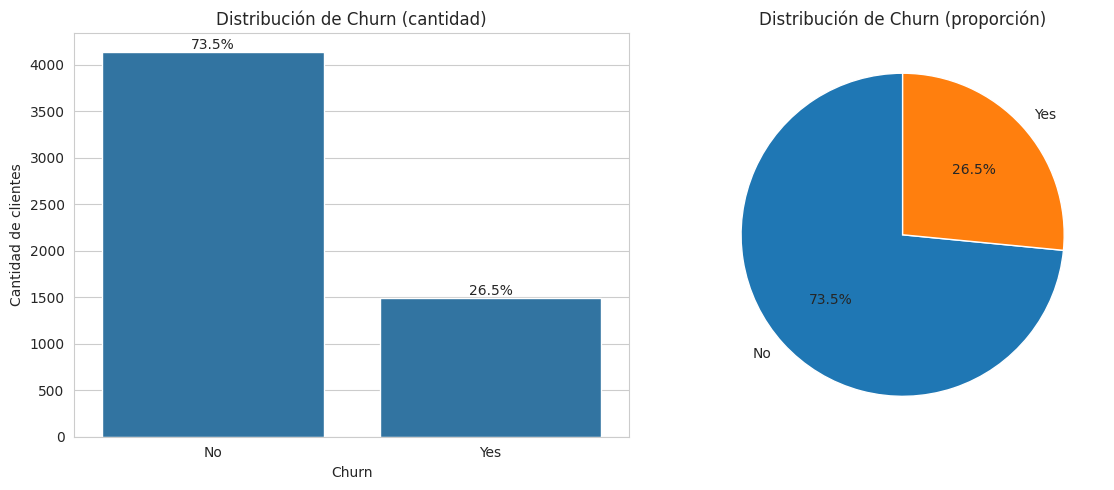

In [ ]:
# --- Distribución de la variable objetivo (Churn) ---
print(train_df['Churn'].value_counts())
print(train_df['Churn'].value_counts(normalize=True).round(3) * 100)

churn_counts = train_df['Churn'].value_counts()
total = len(train_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de barras con el porcentaje sobre cada barra
sns.countplot(x='Churn', data=train_df, ax=axes[0])
for p in axes[0].patches:
    porcentaje = 100 * p.get_height() / total
    axes[0].annotate(f'{porcentaje:.1f}%',
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom', fontsize=10)
axes[0].set_title('Distribución de Churn (cantidad)')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel('Cantidad de clientes')

# Gráfico de torta para visualizar la proporción entre clases
axes[1].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Distribución de Churn (proporción)')

plt.tight_layout()
plt.show()

**Pregunta:** ¿Las clases están balanceadas o desbalanceadas? ¿Qué implicancia tiene esto sobre qué métricas conviene priorizar (Accuracy vs. Precision/Recall/F1/ROC-AUC)?

La variable objetivo presenta un **desbalance leve**: aproximadamente un 73% de los clientes permanece en el servicio y un 27% abandona. Una proporción de clase minoritaria de entre 20% y 40% se considera un desbalance leve, por lo que la clase minoritaria mantiene una representación suficiente.

Por esta razón **no se aplica ninguna de las tres técnicas de balanceo vistas en clase**: ni el ajuste de pesos (`class_weight='balanced'`), ni el sobremuestreo (RandomOverSampler / SMOTE), ni el submuestreo (RandomUnderSampler). Con 1495 casos de churn el modelo tiene suficientes ejemplos de la clase minoritaria para aprender, y cualquiera de esas técnicas distorsionaría las probabilidades predichas a cambio de un beneficio incierto. Se deja constancia de que, si el objetivo del negocio fuera maximizar la detección aun a costa de más falsas alarmas, `class_weight='balanced'` sería la primera opción a evaluar.

Sin embargo, el desbalance sí condiciona la elección de métricas. La **Accuracy resulta engañosa**: un modelo que predijera "No Churn" para todos los clientes alcanzaría un 73% de aciertos sin detectar un solo caso de abandono. Por eso la evaluación se apoya principalmente en **Recall** (qué porcentaje de los clientes que se van logramos detectar), **Precision** (qué porcentaje de las alertas son correctas), **F1-score** (el equilibrio entre ambas) y **ROC-AUC**, que mide la capacidad de discriminación con independencia del umbral y es la métrica de comparación principal indicada en la consigna.

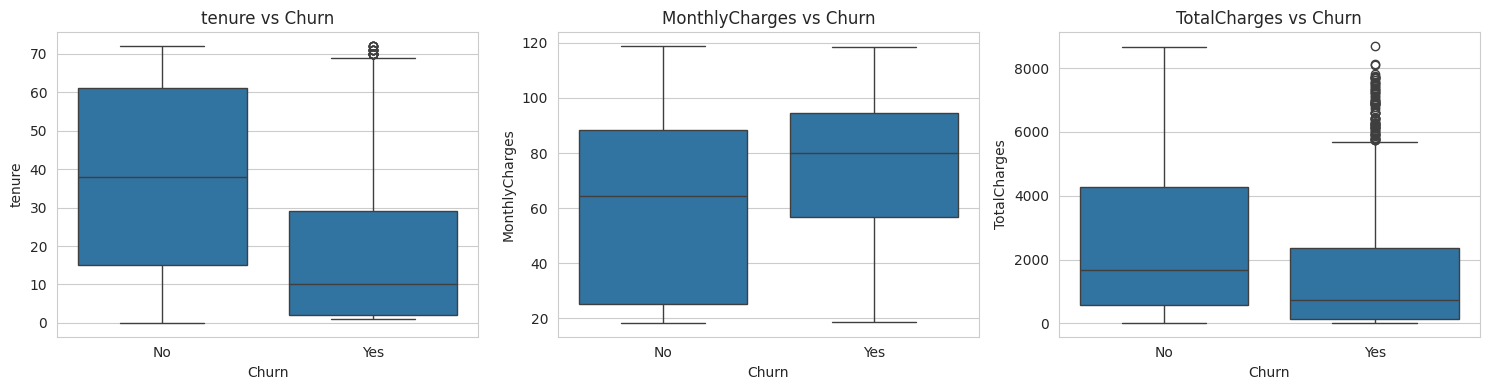

In [ ]:
# --- Variables numéricas vs. Churn ---
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, len(num_cols), figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='Churn', y=col, data=train_df, ax=ax)
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()


Los boxplots muestran diferencias claras entre los clientes que abandonan el servicio y los que permanecen:

- **tenure**: los clientes que hacen churn presentan una menor antigüedad en la empresa. Esto sugiere que el riesgo de abandono es mayor durante los primeros meses de relación con la compañía.
- **MonthlyCharges**: los clientes que abandonan tienden a tener cargos mensuales más elevados, lo que indica que el costo del servicio podría influir en la decisión de cancelar.
- **TotalCharges**: los clientes que permanecen acumulan un mayor gasto total, explicado principalmente por su mayor permanencia. Esta variable muestra una fuerte relación con `tenure`.

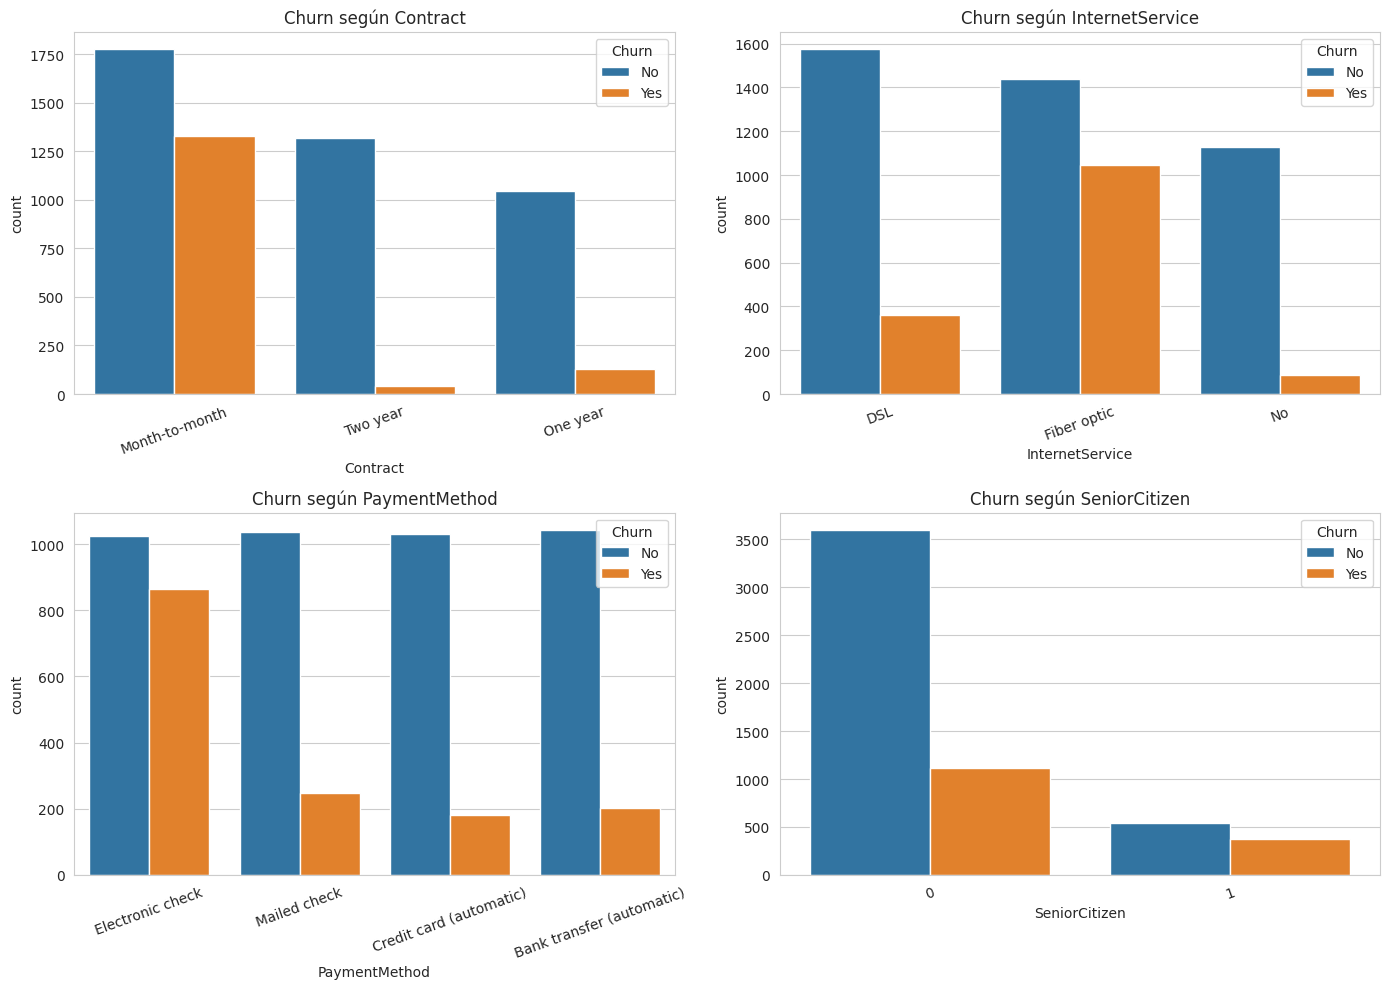

In [ ]:
# --- Variables categóricas clave vs. Churn ---
cat_vars_interes = ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), cat_vars_interes):
    sns.countplot(x=col, hue='Churn', data=train_df, ax=ax)
    ax.set_title(f'Churn según {col}')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


In [ ]:
# --- Tasa de churn dentro de cada categoría ---
# Los countplots muestran cantidades absolutas, que resultan engañosas cuando los grupos
# tienen tamaños muy distintos (por ejemplo, hay muchos más clientes no senior que senior).
# Calculamos la proporción de abandono dentro de cada grupo, como se hizo en clase.
for col in cat_vars_interes:
    tasa = train_df.groupby(col)['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
    print(f'--- Tasa de churn según {col} (%) ---')
    print(tasa.round(1).sort_values(ascending=False).to_string())
    print()

--- Tasa de churn según Contract (%) ---
Contract
Month-to-month    42.7
One year          11.1
Two year           2.9

--- Tasa de churn según InternetService (%) ---
InternetService
Fiber optic    42.1
DSL            18.7
No              7.2

--- Tasa de churn según PaymentMethod (%) ---
PaymentMethod
Electronic check             45.7
Mailed check                 19.3
Bank transfer (automatic)    16.2
Credit card (automatic)      14.9

--- Tasa de churn según SeniorCitizen (%) ---
SeniorCitizen
1    41.1
0    23.7



Al mirar las **tasas de churn dentro de cada grupo** (y no solo los conteos absolutos), los patrones se vuelven mucho más claros:

- **Contract**: es la variable más discriminante de todo el dataset. Los contratos *Month-to-month* abandonan al **42.7%**, frente a **11.1%** en *One year* y apenas **2.9%** en *Two year*.
- **PaymentMethod**: *Electronic check* alcanza un **45.7%** de churn, muy por encima de *Mailed check* (19.3%), *Bank transfer* (16.2%) y *Credit card* (14.9%). Los métodos automáticos retienen notablemente mejor.
- **InternetService**: *Fiber optic* abandona al **42.1%**, contra **18.7%** de DSL y **7.2%** de quienes no tienen Internet, lo que sugiere una brecha entre el precio del servicio y la satisfacción percibida.
- **SeniorCitizen**: aquí es donde el conteo absoluto más engaña. En cantidad, abandonan más los no seniors, simplemente porque son un grupo mucho más numeroso; en proporción, los seniors abandonan al **41.1%** frente al **23.7%** de los no seniors.

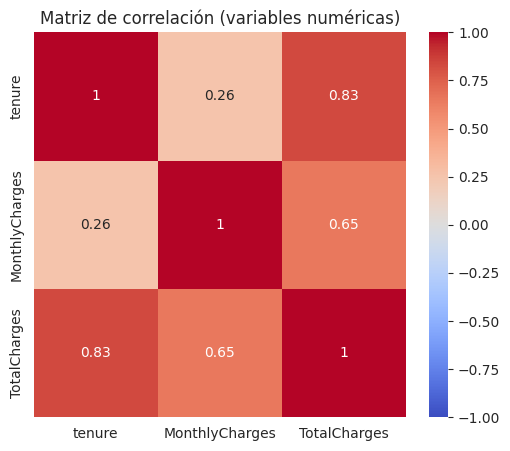

In [ ]:
# --- Correlación entre variables numéricas ---
plt.figure(figsize=(6, 5))
corr = train_df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación (variables numéricas)')
plt.show()


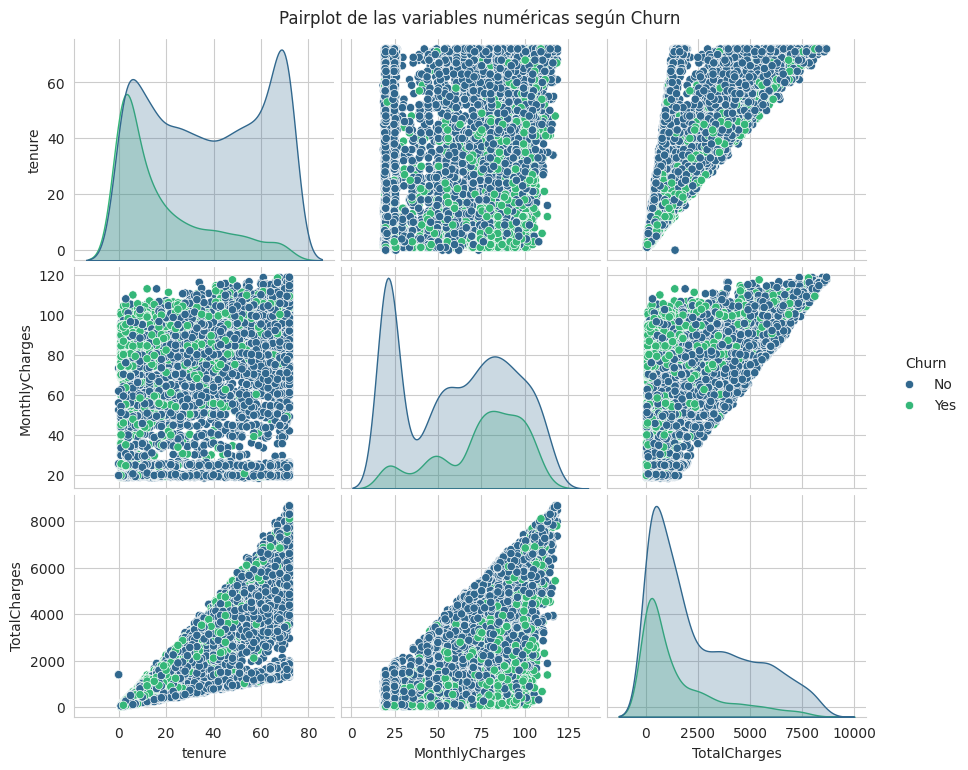

In [ ]:
# --- Relación conjunta entre las variables numéricas, diferenciada por Churn ---
sns.pairplot(
    train_df[num_cols + ['Churn']],
    hue='Churn',
    palette='viridis',
    height=2.5,
    aspect=1.2
)
plt.suptitle('Pairplot de las variables numéricas según Churn', y=1.02)
plt.show()

**Matriz de correlación y pairplot:**

- **tenure** y **TotalCharges** presentan una fuerte relación positiva (r = 0.83), ya que los clientes con mayor antigüedad acumulan un mayor monto total facturado.
- **MonthlyCharges** y **TotalCharges** muestran una correlación moderada (r = 0.65): los clientes con mayores cargos mensuales tienden a acumular mayores cargos totales, aunque esta relación también depende del tiempo de permanencia.
- La relación entre **tenure** y **MonthlyCharges** es débil (r = 0.26), indicando que la antigüedad del cliente no determina el valor de su factura mensual, por lo que ambas variables aportan información complementaria.

En las distribuciones por clase se observa que los clientes que abandonan el servicio se concentran principalmente en valores bajos de antigüedad y de cargos totales, y presentan una mayor concentración en valores relativamente altos de `MonthlyCharges`.

**Pregunta:** ¿Qué variables parecen tener mayor relación con el abandono de clientes? (ej: tipo de contrato, antigüedad, cargos mensuales)

**Síntesis del EDA.** Las variables con mayor capacidad para explicar el abandono son el **tipo de contrato** (42.7% de churn en *Month-to-month* contra 2.9% en *Two year*), el **método de pago** (45.7% en *Electronic check*), el **servicio de Internet** (42.1% en *Fiber optic*) y la **antigüedad**, ya que el riesgo se concentra en los primeros meses de relación con la compañía.

Entre las numéricas, `tenure` y `TotalCharges` están fuertemente correlacionadas (r = 0.83) porque el gasto acumulado crece con la permanencia, mientras que `MonthlyCharges` aporta información complementaria (r = 0.26 con `tenure`).

Estos resultados respaldan el uso de todas estas variables como predictoras en los modelos que se desarrollan a continuación.

---
# **3. Preprocesamiento de Datos**

Preparamos los datos para que puedan ser utilizados por los modelos. Las decisiones tomadas en esta sección, y su justificación, son las siguientes:

| # | Decisión | Justificación |
|---|---|---|
| 3.1 | Eliminar `customerID` | Es un identificador único por cliente. No contiene información generalizable y su inclusión solo aportaría ruido. |
| 3.2 | `TotalCharges = 0` en los clientes con `tenure = 0` | Corrige la imputación por mediana detectada en el EDA. Un cliente con cero meses de antigüedad no acumuló facturación. |
| 3.3 | Codificar `Churn` como 1/0 | Los algoritmos de scikit-learn requieren que la variable objetivo sea numérica. |
| 3.4 | One-Hot Encoding con `drop_first=True` | Las 15 variables categóricas no pueden procesarse directamente. Se descarta una categoría por variable para evitar multicolinealidad perfecta entre las dummies. Luego se **alinean las columnas** de train y test para garantizar que ambos conjuntos compartan exactamente la misma estructura. |
| 3.5 | División 80/20 con `stratify` | Necesitamos un conjunto de validación no visto para estimar el rendimiento. La estratificación conserva la proporción 73/27 de la variable objetivo en ambas partes, algo importante dado el desbalance. |
| 3.6 | Estandarizar con `StandardScaler` | Imprescindible para kNN, que decide por distancias y se vería dominado por las variables de mayor magnitud (`TotalCharges` frente a dummies 0/1), y favorece la convergencia de la Regresión Logística. El escalador se ajusta **solo con los datos de entrenamiento** y se aplica a validación, para no filtrar información del conjunto de evaluación hacia el modelo. |

No se aplica imputación de valores faltantes porque el dataset no presenta nulos, ni se eliminan filas duplicadas porque no existen (ambos verificados en la sección 2).

In [ ]:
# --- 3.1 Guardar customerID de test y eliminar la columna identificadora ---
test_ids = test_df['customerID'].copy()
train_proc = train_df.drop(columns=['customerID'])
test_proc = test_df.drop(columns=['customerID'])

# --- 3.2 Corregir TotalCharges en los clientes con tenure = 0 ---
# En el EDA detectamos que estos 11 clientes traían la mediana de la variable en lugar de su
# valor real. Al tener cero meses de antigüedad, el valor coherente es 0.
train_proc.loc[train_proc['tenure'] == 0, 'TotalCharges'] = 0.0
test_proc.loc[test_proc['tenure'] == 0, 'TotalCharges'] = 0.0

print('Registros corregidos -> train:', (train_proc['tenure'] == 0).sum(),
      '| test:', (test_proc['tenure'] == 0).sum())
print('train_proc:', train_proc.shape, '| test_proc:', test_proc.shape)

Registros corregidos -> train: 8 | test: 3
train_proc: (5634, 20) | test_proc: (1409, 19)


In [ ]:
# --- 3.3 Codificar la variable objetivo (Yes/No -> 1/0) ---
# La variable Churn se convierte a formato numérico para que pueda ser utilizada por los algoritmos de Machine Learning:
# Yes = 1 (el cliente abandona el servicio)
# No = 0 (el cliente permanece en la compañía).
TARGET = 'Churn'

if not pd.api.types.is_numeric_dtype(train_proc[TARGET]):
    train_proc[TARGET] = train_proc[TARGET].astype(str).str.strip().str.lower().map({'yes': 1, 'no': 0})

print('Valores únicos del target luego de mapear:', train_proc[TARGET].unique())
print('Nulos en target:', train_proc[TARGET].isnull().sum())

Valores únicos del target luego de mapear: [0 1]
Nulos en target: 0


In [ ]:
# --- 3.4 One-Hot Encoding de variables categóricas ---
# Nota: test.csv NO tiene la columna Churn, por eso se codifica por separado
# y luego se alinean las columnas entre train y test.
cat_features = train_proc.drop(columns=[TARGET]).select_dtypes(include=['object', 'string']).columns.tolist()
print('Variables categóricas a codificar:', cat_features)

X_train_full = pd.get_dummies(train_proc.drop(columns=[TARGET]), columns=cat_features, drop_first=True)
X_test_final = pd.get_dummies(test_proc, columns=cat_features, drop_first=True)

# Alinear columnas (por si alguna categoría aparece en un set y no en el otro)
X_train_full, X_test_final = X_train_full.align(X_test_final, join='left', axis=1, fill_value=0)

y_train_full = train_proc[TARGET].astype(int)

print('X_train_full:', X_train_full.shape, ' | X_test_final:', X_test_final.shape)

Variables categóricas a codificar: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
X_train_full: (5634, 30)  | X_test_final: (1409, 30)


In [ ]:
# --- 3.5 Separación en train / validación ---
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

print('Train:', X_train.shape, ' Validación:', X_val.shape, ' Test a predecir:', X_test_final.shape)

Train: (4507, 30)  Validación: (1127, 30)  Test a predecir: (1409, 30)


In [ ]:
# --- 3.6 Escalado de variables ---
# Se estandarizan las variables (media 0 y desvío 1). Es imprescindible para kNN, que decide
# en función de distancias y se vería dominado por las variables de mayor magnitud
# (p. ej. TotalCharges frente a las dummies 0/1), y favorece la convergencia de la
# Regresión Logística. El escalador se ajusta SOLO con los datos de entrenamiento y luego se
# aplica a validación, para no filtrar información del set de validación hacia el modelo.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

**Estado de los datos al finalizar el preprocesamiento.** Partimos de 21 columnas y llegamos a 30 variables predictoras numéricas, todas estandarizadas y sin valores faltantes. Los conjuntos quedan divididos en 4507 registros de entrenamiento, 1127 de validación (manteniendo la proporción 73/27 de la variable objetivo) y 1409 de test para la entrega final, con idéntica estructura de columnas en los tres. Los datos están listos para el modelado.

# **4. Modelado y Evaluación**

## Ahora entrenaremos y evaluaremos los tres modelos requeridos:
## Regresión Logística, k-NN y Naive Bayes.


In [ ]:
# --- 4.1 Regresión Logística ---
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_val_scaled)
y_proba_lr = log_reg.predict_proba(X_val_scaled)[:, 1]


k =   5  ->  ROC AUC promedio = 0.7738


k =  15  ->  ROC AUC promedio = 0.8142
k =  25  ->  ROC AUC promedio = 0.8234


k =  50  ->  ROC AUC promedio = 0.8283
k =  75  ->  ROC AUC promedio = 0.8297


k = 100  ->  ROC AUC promedio = 0.8300


k = 150  ->  ROC AUC promedio = 0.8275


k = 300  ->  ROC AUC promedio = 0.8220

Mejor k encontrado: 100


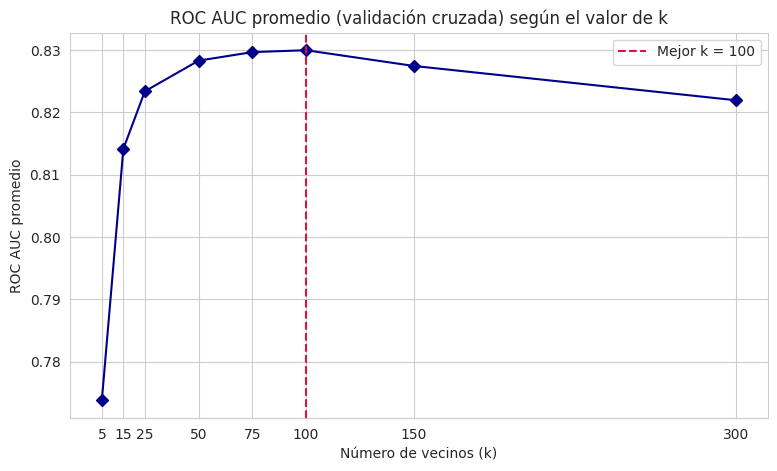

In [ ]:
# --- 4.2 kNN: búsqueda del mejor número de vecinos (k) ---
# Tal como se hizo en clase, probamos distintos valores de k y evaluamos cada uno mediante
# validación cruzada (5 particiones) sobre el set de entrenamiento, usando ROC AUC como
# criterio de selección. Se exploran valores crecientes hasta detectar el punto donde el
# rendimiento deja de mejorar.
k_values = [5, 15, 25, 50, 75, 100, 150, 300]
roc_auc_por_k = []

for k in k_values:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_scaled, y_train,
                             cv=5, scoring='roc_auc')
    roc_auc_por_k.append(scores.mean())
    print(f'k = {k:>3}  ->  ROC AUC promedio = {scores.mean():.4f}')

mejor_k = k_values[int(np.argmax(roc_auc_por_k))]
print(f'\nMejor k encontrado: {mejor_k}')

plt.figure(figsize=(9, 5))
plt.plot(k_values, roc_auc_por_k, marker='D', color='darkblue')
plt.axvline(mejor_k, color='crimson', linestyle='--', label=f'Mejor k = {mejor_k}')
plt.title('ROC AUC promedio (validación cruzada) según el valor de k')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('ROC AUC promedio')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Entrenamos el kNN con el mejor k y predecimos sobre el set de validación
knn = KNeighborsClassifier(n_neighbors=mejor_k)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_val_scaled)
y_proba_knn = knn.predict_proba(X_val_scaled)[:, 1]

In [ ]:
# --- 4.3 Naive Bayes ---
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_val_scaled)
y_proba_nb = nb_model.predict_proba(X_val_scaled)[:, 1]


In [ ]:
# --- 4.4 Comparación de métricas (sobre el set de validación) ---
def calcular_metricas(nombre, y_true, y_pred, y_proba):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC AUC': roc_auc_score(y_true, y_proba),
    }

resultados = pd.DataFrame([
    calcular_metricas('Regresión Logística', y_val, y_pred_lr, y_proba_lr),
    calcular_metricas(f'kNN (k={mejor_k})', y_val, y_pred_knn, y_proba_knn),
    calcular_metricas('Naive Bayes', y_val, y_pred_nb, y_proba_nb),
]).set_index('Modelo').round(3)

resultados

,Accuracy,Precision,Recall,F1-Score,ROC AUC
Modelo,,,,,
Regresión Logística,0.815,0.691,0.545,0.609,0.848
kNN (k=100),0.804,0.650,0.565,0.605,0.839
Naive Bayes,0.666,0.436,0.870,0.580,0.828


In [ ]:
# --- 4.5 Validación cruzada: ¿el resultado depende de la partición elegida? ---
# La tabla anterior se calculó sobre una única división train/validación. Para verificar que
# el ranking de modelos no es producto del azar de esa partición, repetimos la evaluación
# 5 veces con validación cruzada. El promedio indica el rendimiento esperado y el desvío
# indica qué tan estable es cada modelo ante cambios en los datos.
modelos_cv = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    f'kNN (k={mejor_k})': KNeighborsClassifier(n_neighbors=mejor_k),
    'Naive Bayes': GaussianNB(),
}

cv_resultados = []
for nombre, modelo in modelos_cv.items():
    scores = cross_val_score(modelo, X_train_scaled, y_train, cv=5, scoring='roc_auc')
    cv_resultados.append({
        'Modelo': nombre,
        'ROC AUC promedio (5 particiones)': scores.mean().round(4),
        'Desvío entre particiones': scores.std().round(4),
    })

pd.DataFrame(cv_resultados).set_index('Modelo')

,ROC AUC promedio (5 particiones),Desvío entre particiones
Modelo,,
Regresión Logística,0.8453,0.0104
kNN (k=100),0.8300,0.0160
Naive Bayes,0.8207,0.0134


La validación cruzada **confirma el ranking obtenido sobre la partición de validación**: la Regresión Logística mantiene el primer puesto (0.8453), seguida por kNN (0.8300) y Naive Bayes (0.8207). Los desvíos son bajos en los tres casos (entre 0.010 y 0.016), es decir, el rendimiento es estable ante cambios en los datos y la ventaja de la Regresión Logística no es producto del azar de una partición puntual. Además es el modelo más estable de los tres, con el desvío más bajo.

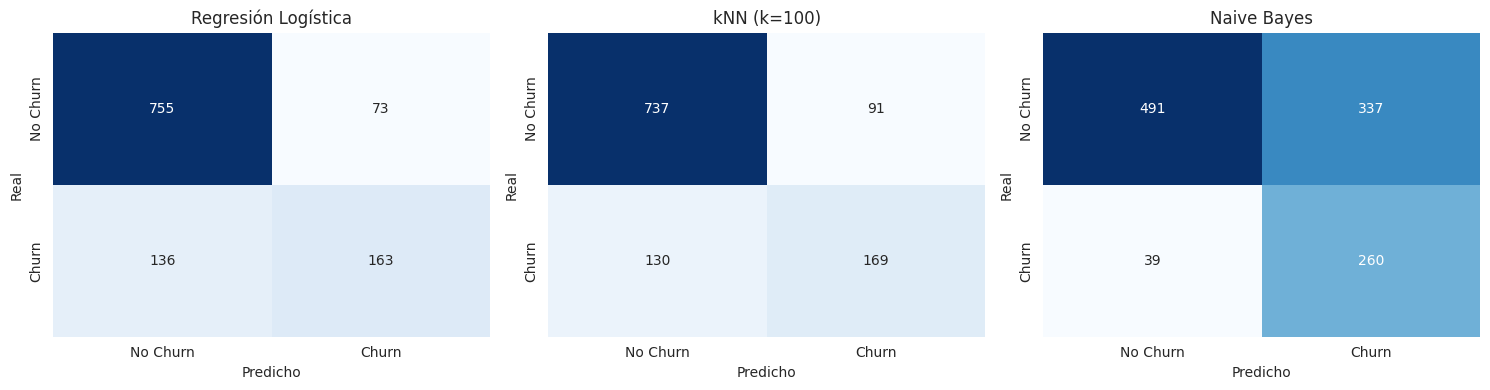

In [ ]:
# --- 4.6 Matrices de confusión ---
modelos_pred = [
    ('Regresión Logística', y_pred_lr),
    (f'kNN (k={mejor_k})', y_pred_knn),
    ('Naive Bayes', y_pred_nb),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, y_pred) in zip(axes, modelos_pred):
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
    ax.set_title(nombre)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')

plt.tight_layout()
plt.show()

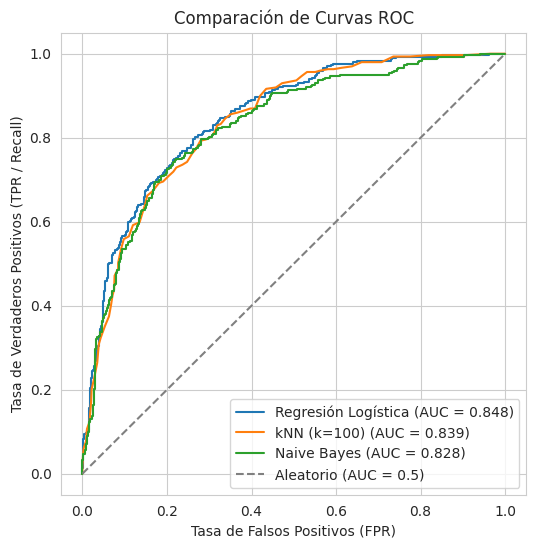

In [ ]:
# --- 4.7 Curvas ROC comparadas ---
# La curva ROC muestra el compromiso entre detectar clientes en riesgo (TPR) y generar
# falsas alarmas (FPR) para todos los umbrales posibles. El área bajo la curva (AUC) es la
# métrica de comparación principal indicada en la consigna.
plt.figure(figsize=(6, 6))
for nombre, y_proba in [
    ('Regresión Logística', y_proba_lr),
    (f'kNN (k={mejor_k})', y_proba_knn),
    ('Naive Bayes', y_proba_nb),
]:
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    auc = roc_auc_score(y_val, y_proba)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Aleatorio (AUC = 0.5)')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
plt.title('Comparación de Curvas ROC')
plt.legend()
plt.show()

### 4.8 Reporte detallado por modelo (sobre validación)

In [ ]:
for nombre, y_pred in modelos_pred:
    print(f'--- {nombre} ---')
    print(classification_report(y_val, y_pred, target_names=['No Churn', 'Churn']))


--- Regresión Logística ---
              precision    recall  f1-score   support

    No Churn       0.85      0.91      0.88       828
       Churn       0.69      0.55      0.61       299

    accuracy                           0.81      1127
   macro avg       0.77      0.73      0.74      1127
weighted avg       0.81      0.81      0.81      1127

--- kNN (k=100) ---
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87       828
       Churn       0.65      0.57      0.60       299

    accuracy                           0.80      1127
   macro avg       0.75      0.73      0.74      1127
weighted avg       0.80      0.80      0.80      1127

--- Naive Bayes ---
              precision    recall  f1-score   support

    No Churn       0.93      0.59      0.72       828
       Churn       0.44      0.87      0.58       299

    accuracy                           0.67      1127
   macro avg       0.68      0.73      0.65      1127
weight

**Regresión Logística.** Obtuvo el mejor desempeño general entre los modelos evaluados: la mayor Accuracy (81.5%), la mayor Precision (69.1%), el mayor F1-score (60.9%) y el mayor ROC-AUC (0.848). Este último valor indica que es el modelo con mejor capacidad para distinguir entre clientes que abandonan y clientes que permanecen, con independencia del umbral de clasificación utilizado. En la matriz de confusión identifica correctamente 163 clientes que efectivamente abandonan y genera solo 73 falsos positivos, aunque mantiene 136 falsos negativos (clientes que se van y el modelo no detecta).

**kNN.** Obtuvo resultados muy cercanos a la Regresión Logística (Accuracy 80.4%, ROC-AUC 0.839, apenas 0.009 por debajo). Detecta algunos clientes en riesgo más (169 verdaderos positivos frente a 163) y tiene menos falsos negativos (130 frente a 136), lo que explica su Recall levemente superior (56.5% frente a 54.5%). Sin embargo, esa mejora en detección viene acompañada de más falsas alarmas (91 falsos positivos frente a 73), por lo que su Precision es menor.

**Naive Bayes.** Presenta un comportamiento claramente distinto, marcado por un Recall muy alto (87%): detecta la gran mayoría de los clientes que realmente abandonan y deja escapar solo 39 casos, siendo el modelo con menos falsos negativos. Ese desempeño tiene un costo elevado: genera 337 falsos positivos, casi cinco veces más que la Regresión Logística, lo que explica su baja Precision (43.6%) y su baja Accuracy (66.6%). El modelo tiende a marcar como potencial churn a una gran cantidad de clientes que finalmente no abandonan.

### 4.9 Variables más influyentes según la Regresión Logística

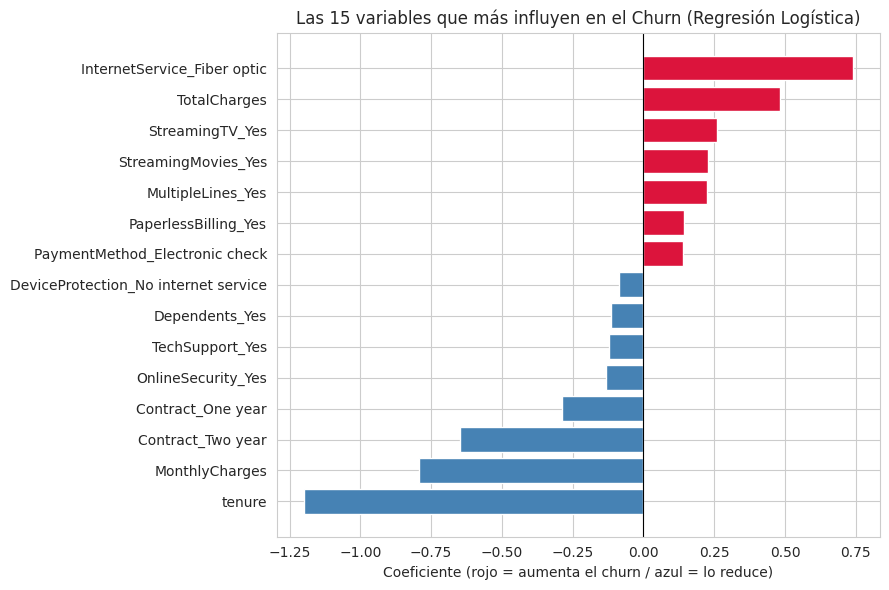

,Variable,Coeficiente
1,tenure,-1.198412
2,MonthlyCharges,-0.791624
10,InternetService_Fiber optic,0.738540
25,Contract_Two year,-0.649051
3,TotalCharges,0.483961
24,Contract_One year,-0.289453
21,StreamingTV_Yes,0.258030
23,StreamingMovies_Yes,0.228650
9,MultipleLines_Yes,0.225691
26,PaperlessBilling_Yes,0.142223


In [ ]:
# Los coeficientes de la Regresión Logística indican cuánto y en qué dirección influye cada
# variable sobre la probabilidad de churn: un coeficiente positivo aumenta el riesgo de
# abandono y uno negativo lo reduce. Como las variables están estandarizadas, las magnitudes
# son comparables entre sí.
coef_df = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente': log_reg.coef_[0]
}).sort_values('Coeficiente', key=abs, ascending=False)

top_n = 15
top_coefs = coef_df.head(top_n).sort_values('Coeficiente')
colores = ['crimson' if c > 0 else 'steelblue' for c in top_coefs['Coeficiente']]

plt.figure(figsize=(9, 6))
plt.barh(top_coefs['Variable'], top_coefs['Coeficiente'], color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f'Las {top_n} variables que más influyen en el Churn (Regresión Logística)')
plt.xlabel('Coeficiente (rojo = aumenta el churn / azul = lo reduce)')
plt.tight_layout()
plt.show()

coef_df.head(top_n)

**Interpretación de los coeficientes.** La antigüedad (`tenure`) es el predictor de mayor peso y actúa reduciendo fuertemente la probabilidad de abandono, seguida por `Contract_Two year`: los contratos largos son el principal factor de retención. En sentido opuesto, `InternetService_Fiber optic` es la variable que más aumenta el riesgo de churn.

Un punto que merece aclaración: `MonthlyCharges` aparece con coeficiente negativo y `TotalCharges` con coeficiente positivo, en aparente contradicción con lo observado en el EDA. Esto se explica por la **multicolinealidad** detectada en la sección 2: `tenure` y `TotalCharges` están fuertemente correlacionadas (r = 0.83), y el efecto del precio alto ya queda capturado por `InternetService_Fiber optic`. En presencia de variables correlacionadas, los coeficientes reparten el efecto entre sí y su signo deja de ser interpretable de forma aislada.

**Decisión:** se conservan ambas variables. El objetivo del proyecto es predictivo y no inferencial, y la multicolinealidad no degrada la capacidad predictiva del modelo (el ROC-AUC es el más alto de los tres) sino únicamente la lectura individual de los coeficientes. Por lo tanto, la interpretación se apoya en el conjunto de variables y en las relaciones bivariadas del EDA, que siguen siendo válidas para describir el perfil del cliente que abandona.

## 4.10 Predicciones finales sobre `test.csv`

`test.csv` no contiene la columna `Churn` (es el conjunto que se usa para la entrega). Seleccionamos el modelo con mejor ROC AUC en validación, lo **reentrenamos con el 100% de los datos de entrenamiento** —práctica estándar para aprovechar toda la información disponible una vez elegido el modelo— y generamos el archivo final de predicciones.

In [ ]:
# --- Selección automática del mejor modelo según ROC AUC de la sección 4.4 ---
# Se elige de forma automática para que, si cambian los datos o el ranking de modelos,
# no haya que modificar esta celda a mano.
modelos_dict = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    f'kNN (k={mejor_k})': KNeighborsClassifier(n_neighbors=mejor_k),
    'Naive Bayes': GaussianNB(),
}

nombre_mejor_modelo = resultados['ROC AUC'].idxmax()
print(f"Modelo seleccionado (mayor ROC AUC en validación): {nombre_mejor_modelo} "
      f"(ROC AUC = {resultados.loc[nombre_mejor_modelo, 'ROC AUC']})")

# Reentrenamiento con el 100% de train.csv (entrenamiento + validación).
# El escalador también se reajusta sobre el conjunto completo y se aplica a test.csv.
scaler_final = StandardScaler()
X_train_full_scaled = scaler_final.fit_transform(X_train_full)
X_test_final_scaled = scaler_final.transform(X_test_final)

modelo_final = modelos_dict[nombre_mejor_modelo]
modelo_final.fit(X_train_full_scaled, y_train_full)

y_pred_final = modelo_final.predict(X_test_final_scaled)
y_proba_final = modelo_final.predict_proba(X_test_final_scaled)[:, 1]

# El archivo de entrega lleva el identificador del cliente y la predicción de Churn.
submission = pd.DataFrame({
    'customerID': test_ids,
    'Churn': np.where(y_pred_final == 1, 'Yes', 'No'),
})
submission.to_csv('submission_churn.csv', index=False)
print(f'\nPredicciones guardadas en submission_churn.csv - {submission.shape[0]} clientes')
print('Distribución de las predicciones:')
print(submission['Churn'].value_counts())

# La probabilidad estimada no forma parte del archivo de entrega, pero la mostramos porque
# permite priorizar a qué clientes contactar primero en una campaña de retención.
submission.assign(Probabilidad_Churn=y_proba_final.round(4)).head(10)

Modelo seleccionado (mayor ROC AUC en validación): Regresión Logística (ROC AUC = 0.848)

Predicciones guardadas en submission_churn.csv - 1409 clientes
Distribución de las predicciones:
Churn
No     1087
Yes     322
Name: count, dtype: int64


,customerID,Churn,Probabilidad_Churn
0,4376-KFVRS,No,0.0450
1,2754-SDJRD,Yes,0.6832
2,9917-KWRBE,No,0.0565
3,0365-GXEZS,No,0.4078
4,9385-NXKDA,No,0.0217
5,4686-UXDML,Yes,0.6035
6,2227-JRSJX,No,0.4519
7,4830-FAXFM,No,0.1309
8,1830-IPXVJ,No,0.0029
9,4690-LLKUA,No,0.3941


---
# **5. Conclusiones**

### ¿Qué modelo funcionó mejor y por qué creemos que fue así?

La comparación demuestra la importancia de evaluar múltiples métricas en un problema con clases desbalanceadas. Si solo se considerara la Accuracy, la Regresión Logística parecería claramente superior y Naive Bayes sería descartado; sin embargo, al analizar el Recall y las matrices de confusión se observa que Naive Bayes es el que más clientes en riesgo detecta.

**Se selecciona la Regresión Logística como modelo final.** Alcanzó el mayor ROC-AUC (0.848), lo que indica la mejor capacidad de discriminación entre clientes que abandonan y clientes que permanecen, y ofrece el mejor equilibrio entre Precision y Recall: detecta clientes en riesgo sin generar una cantidad excesiva de falsas alarmas. La validación cruzada confirmó que esta ventaja no depende de la partición elegida, ya que mantiene el primer puesto con el desvío más bajo de los tres modelos.

Creemos que funcionó mejor porque la relación entre las variables predictoras y el churn es en gran medida **lineal y aditiva** en la escala del logit: el tipo de contrato, la antigüedad o el método de pago desplazan la probabilidad de abandono de forma consistente, que es exactamente el tipo de estructura que este modelo captura. Naive Bayes, en cambio, asume que las variables son independientes entre sí, y en este dataset ese supuesto se incumple con claridad (`tenure` y `TotalCharges` tienen una correlación de 0.83). Eso se refleja en su resultado: marca como churn a 337 clientes que en realidad no abandonan, casi cinco veces más que la Regresión Logística.

Conviene señalar que **la diferencia entre los tres modelos es acotada**: el ROC-AUC va de 0.828 a 0.848, es decir, los tres discriminan razonablemente bien y kNN queda a solo 0.009 del ganador. Lo que realmente los distingue no es la capacidad de discriminación sino **cómo reparten los errores** entre falsos positivos y falsos negativos.

Por eso **la elección depende del objetivo de negocio**. Si la prioridad fuera maximizar la detección de clientes en riesgo asumiendo el costo de contactar a muchos que no iban a irse, Naive Bayes sería preferible por su Recall del 87%. Dado que el objetivo del proyecto es identificar clientes con probabilidad de abandono manteniendo un equilibrio entre detección y precisión, la Regresión Logística es la opción adecuada. Como valor agregado, es además el modelo más interpretable de los tres: sus coeficientes permiten explicar al área de negocio *por qué* un cliente fue marcado como riesgoso.

### ¿Cuáles fueron las características más importantes o los descubrimientos más interesantes del EDA?

El EDA fue determinante para identificar las variables con mayor relación con el abandono, y los coeficientes del modelo final **confirmaron a `tenure` y `Contract` como los factores dominantes**:

- **Antigüedad (`tenure`)**: es el predictor de mayor peso del modelo y actúa reduciendo el riesgo. Los primeros meses de la relación son el período crítico para la retención.
- **Tipo de contrato (`Contract`)**: la variable más discriminante del EDA (42.7% de churn en *Month-to-month* contra 2.9% en *Two year*) y el segundo coeficiente en magnitud. Los contratos largos son el principal factor de retención.
- **Servicio de Internet (`InternetService`)**: *Fiber optic* abandona al 42.1% y es la variable que más aumenta el riesgo según el modelo (coeficiente +0.74), sugiriendo una brecha entre el precio del servicio y la satisfacción percibida.
- **Método de pago (`PaymentMethod`)**: *Electronic check* concentra un 45.7% de churn frente a menos del 20% en los métodos automáticos.
- **Cargos mensuales (`MonthlyCharges`)**: el EDA muestra que quienes abandonan pagan más, pero su coeficiente en el modelo no es interpretable de forma aislada por la multicolinealidad explicada en la sección 4.9. La evidencia sólida sobre el efecto del precio proviene de `InternetService_Fiber optic`.

El descubrimiento más interesante es que el perfil de mayor riesgo es un patrón combinado y accionable: **cliente nuevo, con contrato mes a mes, fibra óptica y pago por cheque electrónico**. Es un segmento sobre el que el negocio puede intervenir directamente, por ejemplo incentivando la migración a contratos anuales o a débito automático durante los primeros meses.

### ¿Qué desafíos encontraron y cómo los resolvieron?

1. **Una imputación defectuosa oculta en los datos.** Fue el hallazgo más interesante del trabajo. El dataset no presentaba ningún valor nulo, por lo que a primera vista no requería limpieza. Sin embargo, al controlar la coherencia de `TotalCharges` frente a `tenure` descubrimos que los 11 clientes con `tenure = 0` tenían todos exactamente el mismo valor, 1397.475, que resultó ser la **mediana** de la variable y no aparecía en ninguna otra fila. Es decir, los blancos originales ya venían imputados con la mediana por quien preparó los datos, lo que asigna a un cliente de cero meses el gasto acumulado mediano de la cartera. Lo resolvimos asignándoles `TotalCharges = 0`, el valor coherente con su antigüedad. La lección es que **la ausencia de nulos no equivale a ausencia de problemas de calidad**.

2. **Desbalance de clases.** La variable objetivo presenta un 73% de No Churn frente a un 27% de Churn. Un modelo podría alcanzar una Accuracy alta prediciendo siempre la clase mayoritaria sin detectar ningún abandono. Lo resolvimos priorizando métricas adecuadas (Recall, Precision, F1 y ROC-AUC) por sobre la Accuracy, y usando una división estratificada (`stratify=y`) para conservar la proporción de clases entre entrenamiento y validación.

3. **Conteos absolutos que llevaban a conclusiones erróneas.** Los primeros gráficos del EDA mostraban más abandonos entre los clientes no seniors, lo que sugería que la edad no era relevante. Al calcular las **tasas dentro de cada grupo** quedó claro lo contrario: los seniors abandonan al 41.1% frente al 23.7% de los no seniors, y solo parecían menos porque son un grupo mucho más chico.

4. **Codificación de variables categóricas.** El dataset contiene 15 variables categóricas que los algoritmos no pueden procesar directamente. Aplicamos One-Hot Encoding con `drop_first=True` para evitar multicolinealidad, y **alineamos las columnas de train y test** para garantizar que ambos conjuntos compartieran exactamente la misma estructura antes de predecir.

5. **Selección del hiperparámetro k en kNN.** Los valores bajos habituales (k=5) daban resultados pobres (ROC AUC 0.774). Recorrimos un rango amplio evaluando cada valor con validación cruzada de 5 particiones, lo que mostró que el rendimiento mejoraba de forma sostenida hasta estabilizarse alrededor de k=100 y caer con valores mayores.

**En síntesis**, mediante un preprocesamiento cuidadoso y una evaluación basada en múltiples métricas, la Regresión Logística se estableció como el modelo más adecuado para predecir el abandono de clientes en este contexto, ofreciendo el mejor equilibrio entre la detección de clientes en riesgo y la fiabilidad de las predicciones. El modelo final fue reentrenado con la totalidad de los datos de entrenamiento y sus predicciones sobre `test.csv` se entregan en el archivo `submission_churn.csv`.